# Liveability exploration

**Approach.** Join cleaned rent.com.au listings to amenity distances, aggregate to SA2, then model mean amenity distance and rent per bedroom against CBD distance. Residuals from those fits form an affordability–amenity tradeoff ("renter score").

**Assumptions.** Straight-line distance is a fair proxy for access; SA2 means (with a minimum listing count) represent the area; CBD distance is the main spatial control.

**Limitations / difficulty.** Amenity features are nearest-distance only (not quality or network travel time); listings are a scraped snapshot with uneven SA2 coverage; residuals can reflect sparse samples as much as true under/over-pricing.

## Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter, NullLocator
from shapely.geometry import Point
import statsmodels.api as sm

ROOT = Path("../..")
DATA = ROOT / "data"
FIGS = Path(".")  # PNGs land next to the notebook (same as alice_vs_bob.png)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

# ── Slide canvases ────────────────────────────────────────────────────────────
# Every PNG is exported at EXACTLY one of these sizes (no bbox="tight" cropping).
# Insert each image at the full slide width (13.33 in on a 16:9 slide) and the
# text will be the same physical size on every slide — no more mismatched fonts.
SLIDE_W = 13.33
FULL = (SLIDE_W, 6.0)       # one chart under a slide title (16:9 slide is 7.5 in tall)
PAIR = (SLIDE_W, 5.8)       # two panels side by side, full width
HALF = (SLIDE_W / 2, 5.8)   # one panel from a pair, if you ever need it alone
DPI = 200

# ── Palette ───────────────────────────────────────────────────────────────────
POINT = "#4C78A8"   # SA2 dots
FIT = "#E45756"     # fitted trend
INK = "#1a1a1a"     # titles, labels
MUTED = "#5f6368"   # subtitles, annotations
AXIS = "#9aa0a6"    # spines, ticks
GRID = "#ececec"

MARKER_S = 55       # sized for ~300 SA2s in a half-slide panel
POINT_ALPHA = 0.55
FIT_LW = 3.5

# Bad (expensive + far) → neutral → good (cheap + close)
# Stronger ends, narrow neutral band — soft pastels washed out on the diagonal
RENTER_CMAP = LinearSegmentedColormap.from_list(
    "renter_score",
    [
        (0.00, "#D64545"),  # bad: expensive + far
        (0.28, "#E8A090"),
        (0.50, "#F7F2E8"),  # as-expected
        (0.72, "#7FB89A"),
        (1.00, "#2F7D5C"),  # good: cheap + close
    ],
)

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 16,
        "axes.titlesize": 20,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 34,          # leaves room for the grey subtitle line
        "axes.labelsize": 16,
        "axes.labelcolor": INK,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 1.2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "legend.fontsize": 14,
        "legend.frameon": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.dpi": DPI,
        "savefig.bbox": None,         # keep the canvas size fixed (see above)
        "figure.constrained_layout.use": True,
        "figure.constrained_layout.w_pad": 0.15,
        "figure.constrained_layout.h_pad": 0.15,
    }
)


def amenity_short(amenity_col: str) -> str:
    """'nearest_school_km' -> 'nearest school'."""
    return amenity_col.replace("_", " ").removesuffix(" km").strip()


def amenity_noun(amenity_col: str) -> str:
    """'nearest_train_station_km' -> 'train station'."""
    return amenity_short(amenity_col).removeprefix("nearest ").strip()


def style_axes(ax, *, grid="y"):
    """Light grid behind the data; spines/ticks come from rcParams."""
    ax.tick_params(length=5, width=1.1, pad=5)
    if grid:
        ax.grid(True, axis=grid, which="major", color=GRID, linewidth=1.0)
        ax.set_axisbelow(True)
    return ax


def save(fig, name):
    fig.savefig(FIGS / name)
    plt.show()


# Readable ticks for log axes: only "nice" values, no minor-tick clutter.
# Uses 1-2-5 steps for wide ranges and falls back to a finer set for narrow ones
# (e.g. school distances spanning 0.5–2 km would otherwise get a single tick).
_DECADES = 10.0 ** np.arange(-2, 3)
COARSE = np.unique(np.outer(_DECADES, [1, 2, 5]).ravel())
FINE = np.unique(np.outer(_DECADES, [1, 1.5, 2, 3, 4, 5, 7]).ravel())


def nice_ticks(vmin, vmax, max_n=6):
    for cands in (COARSE, FINE):
        ticks = cands[(cands >= vmin * 0.999) & (cands <= vmax * 1.001)]
        if len(ticks) >= 3:
            break
    if len(ticks) > max_n:
        idx = np.linspace(0, len(ticks) - 1, max_n).round().astype(int)
        ticks = ticks[np.unique(idx)]
    return ticks


def log_axis(axis, vmin, vmax, fmt="{:g}"):
    """Put a matplotlib Axis (ax.xaxis / ax.yaxis) on clean log ticks."""
    axis.set_major_locator(plt.FixedLocator(nice_ticks(vmin, vmax)))
    axis.set_major_formatter(FuncFormatter(lambda v, _: fmt.format(v)))
    axis.set_minor_locator(NullLocator())
    axis.set_minor_formatter(NullFormatter())


def scatter_sa2(ax, x, y, **kw):
    """Standard SA2 dot style used on every scatter."""
    return ax.scatter(
        x, y, s=MARKER_S, color=POINT, alpha=POINT_ALPHA,
        edgecolor="white", linewidth=0.4, zorder=2, **kw,
    )


## Data

### Load properties + amenities

- `cleaned_properties.csv` — scraped rent.com.au listings after cleaning
- `listings_with_amenity_distances.csv` — nearest-amenity distances and counts (schools, parks, transit, supermarkets)

Joined on `latitude` / `longitude` (amenity features are unique per location).

In [2]:
listings = pd.read_csv(DATA / "preprocessed_data" / "cleaned_properties.csv")
listings["suburb"] = listings["suburb"].str.strip().str.lower()

amenities = pd.read_csv(DATA / "amenity_data" / "listings_with_amenity_distances.csv")

amenity_cols = [
    "nearest_school_km",
    "school_count_2km",
    "nearest_train_station_km",
    "nearest_park_km",
    "park_count_2km",
    "nearest_supermarket_km",
    "supermarket_count_4km",
    "nearest_tram_stop_km",
    "tram_stop_capped",
    "nearest_bus_stop_km",
    "bus_stop_capped",
]

# Amenity features are identical for a given lat/lon; drop duplicates so the merge stays 1:1
amenities = amenities.drop_duplicates(subset=["latitude", "longitude"])[
    ["latitude", "longitude"] + amenity_cols
]

df = listings.merge(amenities, on=["latitude", "longitude"], how="left")

print(f"listings: {len(listings):,} | amenities (unique locs): {len(amenities):,} | merged: {len(df):,}")
print(f"amenity match rate: {df[amenity_cols[0]].notna().mean():.1%}")
df.head()

listings: 9,232 | amenities (unique locs): 8,090 | merged: 9,232
amenity match rate: 100.0%


,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,walk_score,airconditioning_air-conditioning,airconditioning_ducted,...,services_available_pay_tv,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,nearest_school_km,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,-37.814688,144.941083,"1007/20 Rakaia Way,",docklands,3008,730.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,92.0,0,0,...,0,0,0,0,0,0,0,0,0,0.2239,4,1.7541,0.3272,27,0.2927,47,0.2090,False,0.4570,False
1,-37.813699,144.953926,"4408/601 Little Lonsdale Street,",cbd,3000,670.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,99.0,0,0,...,0,0,0,0,0,0,1,0,0,0.2451,7,0.5049,0.1751,42,0.5418,50,0.1963,False,0.1793,False
2,-37.930804,145.112401,"29 Bond Street,",clayton south,3169,615.0,House,3,1,0.0,3,0,0,0.0,0,0,45,76.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8481,4,1.5133,0.4956,32,0.8235,13,3.0000,True,0.2838,False
3,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,540.0,Apartment,1,1,0.0,1,0,0,0.0,0,0,80,98.0,0,0,...,0,0,0,0,0,0,0,0,0,0.6413,11,0.2585,0.4311,35,0.2379,24,0.0904,False,0.3271,False
4,-37.923180,145.128629,"33/2 Greenfield Drive,",clayton,3168,550.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,65,58.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8972,3,1.1356,0.7598,17,1.0678,12,3.0000,True,0.7769,False


### Aggregate listings to SA2

Choose an amenity column, join listings into Greater Melbourne SA2s, and compute:

1. Mean nearest-amenity distance per SA2
2. Straight-line distance from each SA2 centroid to the CBD (Melbourne GPO)

Amenity, rent, and tradeoff analyses keep only SA2s with at least `MIN_N` listings. The choropleth shows every SA2 with at least one listing.


In [3]:
# Switch amenity here — one of:
#   nearest_school_km, nearest_train_station_km, nearest_park_km,
#   nearest_supermarket_km, nearest_tram_stop_km, nearest_bus_stop_km
AMENITY = "nearest_school_km"
MIN_N = 10  # drop SA2s with fewer listings (noise / one-off extremes)

# Melbourne GPO (approx. CBD reference point)
CBD_LAT, CBD_LON = -37.8136, 144.9631

zones = gpd.read_file(DATA / "geospatial_data" / "Vic_Area_Zones" / "Vic_Area_Zones.shp")
zones = zones[zones["GCC_NAME21"] == "Greater Melbourne"].copy()

# Project to metres for true straight-line distances (GDA2020 / MGA zone 55)
zones_m = zones.to_crs(epsg=7855)
cbd = (
    gpd.GeoSeries([Point(CBD_LON, CBD_LAT)], crs="EPSG:4326")
    .to_crs(zones_m.crs)
    .iloc[0]
)
zones_m["dist_cbd_km"] = zones_m.geometry.centroid.distance(cbd) / 1000.0

clean = df.dropna(subset=["latitude", "longitude", AMENITY]).copy()
points = gpd.GeoDataFrame(
    clean,
    geometry=gpd.points_from_xy(clean["longitude"], clean["latitude"]),
    crs="EPSG:4326",
).to_crs(zones.crs)

joined = gpd.sjoin(points, zones[["SA2_NAME21", "geometry"]], how="inner", predicate="within")

avg_all = (
    joined.groupby("SA2_NAME21")
    .agg(avg_amenity_km=(AMENITY, "mean"), n_listings=("SA2_NAME21", "size"))
    .reset_index()
)
# Choropleth only: every SA2 with at least one listing. Other charts keep MIN_N.
sa2_map = (
    zones_m[["SA2_NAME21", "geometry", "dist_cbd_km"]]
    .merge(avg_all, on="SA2_NAME21", how="inner")
)

n_dropped = int((avg_all["n_listings"] < MIN_N).sum())
avg_by_sa2 = avg_all[avg_all["n_listings"] >= MIN_N].copy()
joined = joined[joined["SA2_NAME21"].isin(avg_by_sa2["SA2_NAME21"])].copy()

sa2 = (
    zones_m[["SA2_NAME21", "geometry", "dist_cbd_km"]]
    .merge(avg_by_sa2, on="SA2_NAME21", how="inner")
)

print(f"AMENITY = {AMENITY} | MIN_N = {MIN_N}")
print(f"Dropped {n_dropped} SA2s with < {MIN_N} listings")
print(f"SA2s retained: {len(sa2):,} / {len(zones_m):,} Greater Melbourne SA2s")
sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km", "n_listings"]].sort_values("dist_cbd_km").head()


AMENITY = nearest_school_km | MIN_N = 10
Dropped 96 SA2s with < 10 listings
SA2s retained: 247 / 361 Greater Melbourne SA2s


,SA2_NAME21,dist_cbd_km,avg_amenity_km,n_listings
17,Melbourne CBD - East,0.492020,0.604344,103
19,Melbourne CBD - West,0.520396,0.594187,226
18,Melbourne CBD - North,0.526832,0.814523,189
23,West Melbourne - Residential,1.299765,0.637317,47
21,Southbank (West) - South Wharf,1.320555,1.043053,95


## Mean amenity distance by SA2

Choropleth of mean nearest-amenity distance across Greater Melbourne SA2s (log colour scale). Change `AMENITY` in the aggregation cell above and re-run from there.

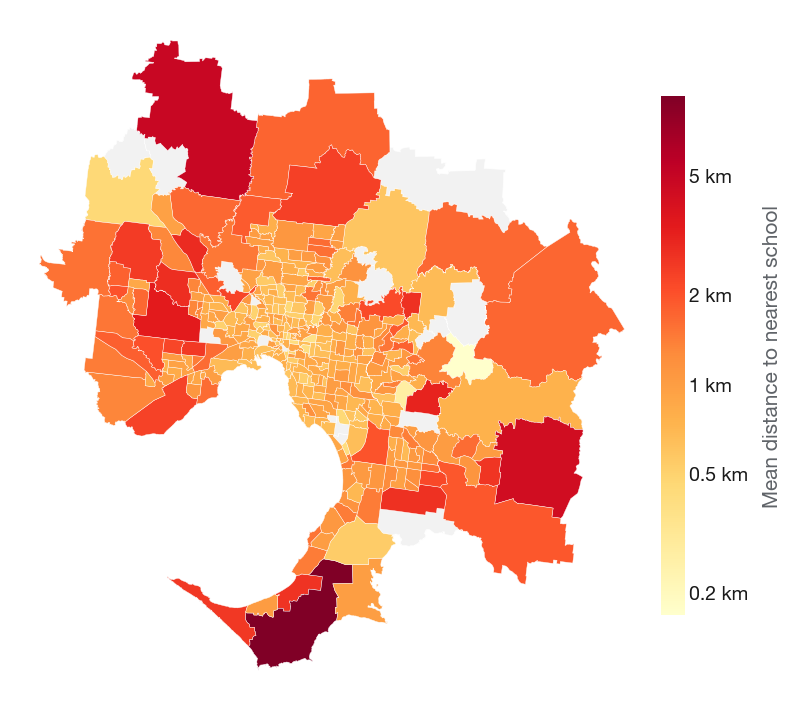

In [4]:
plot_data = sa2_map[sa2_map["avg_amenity_km"] > 0]
vmin, vmax = plot_data["avg_amenity_km"].min(), plot_data["avg_amenity_km"].max()
norm = LogNorm(vmin=vmin, vmax=vmax)
noun = amenity_noun(AMENITY)

# Size the canvas to the map's own shape (instead of a wide 16:9 box with dead space).
# A bit larger than the half-slide charts so the map itself reads bigger.
minx, miny, maxx, maxy = zones_m.total_bounds
map_h = FULL[1] * 1.18
fig_h = map_h + 0.15
fig_w = min(SLIDE_W, map_h * (maxx - minx) / (maxy - miny) + 2.15)  # + colourbar & labels
fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_anchor("W")
zones_m.plot(ax=ax, color="#f2f2f2", edgecolor="white", linewidth=0.4)  # SA2s with no listings
plot_data.plot(
    ax=ax, column="avg_amenity_km", cmap="YlOrRd", norm=norm,
    edgecolor="white", linewidth=0.3,
)
ax.set_axis_off()
ax.set_aspect("equal")

cbar = fig.colorbar(ScalarMappable(norm=norm, cmap="YlOrRd"), ax=ax, shrink=0.75, aspect=22, pad=0.01)
cbar.outline.set_visible(False)
log_axis(cbar.ax.yaxis, vmin, vmax, fmt="{:g} km")
cbar.ax.tick_params(length=0, labelsize=14)
cbar.set_label(f"Mean distance to nearest {noun}", fontsize=15, color=MUTED, labelpad=10)

save(fig, "amenity_choropleth.png")


## Amenity access vs distance to CBD

Each point is one SA2: straight-line centroid→CBD distance vs mean nearest-amenity distance for listings in that SA2. Plotted on natural (linear) axes so you see the raw shape; the fitted view below uses a log amenity axis so the model reads as a straight line.

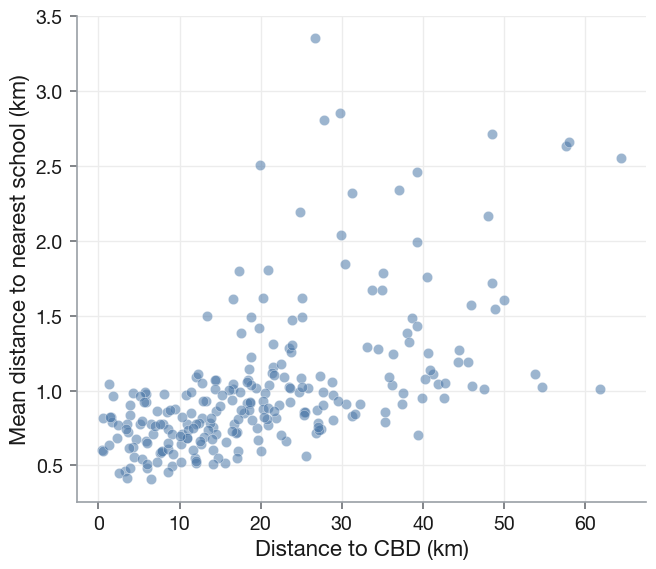

In [5]:
plot_sa2 = sa2[sa2["avg_amenity_km"] > 0]
plot_sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km"]].to_csv(
    "transformed_data/amenity_access_vs_distance_to_cbd.csv", index=False
)

# Natural shape (linear km on both axes) — linearized fit plot is after the model cell
fig, ax = plt.subplots(figsize=HALF)
scatter_sa2(ax, plot_sa2["dist_cbd_km"], plot_sa2["avg_amenity_km"])
style_axes(ax, grid="both")
ax.set_xlabel("Distance to CBD (km)")
ax.set_ylabel(f"Mean distance to {amenity_short(AMENITY)} (km)")
save(fig, "amenity_vs_cbd.png")


### Fitting a model

Log-linear regression: `log(amenity distance) ~ CBD distance`. On a log amenity axis (linear CBD km) the fit is a straight line; on natural axes it is an exponential curve. Predictions are back-transformed from the log scale; `true_pct_above_mean` is how far the observed amenity distance sits above/below the predicted value for that SA2's CBD distance.

In [6]:
fit_df = plot_sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km"]].dropna().copy()
X = sm.add_constant(fit_df["dist_cbd_km"])
y = np.log(fit_df["avg_amenity_km"])

amenity_fit = sm.OLS(y, X).fit()
print(amenity_fit.summary())

                            OLS Regression Results                            
Dep. Variable:         avg_amenity_km   R-squared:                       0.377
Model:                            OLS   Adj. R-squared:                  0.375
Method:                 Least Squares   F-statistic:                     148.3
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           5.43e-27
Time:                        22:50:25   Log-Likelihood:                -61.413
No. Observations:                 247   AIC:                             126.8
Df Residuals:                     245   BIC:                             133.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.4321      0.036    -12.023      

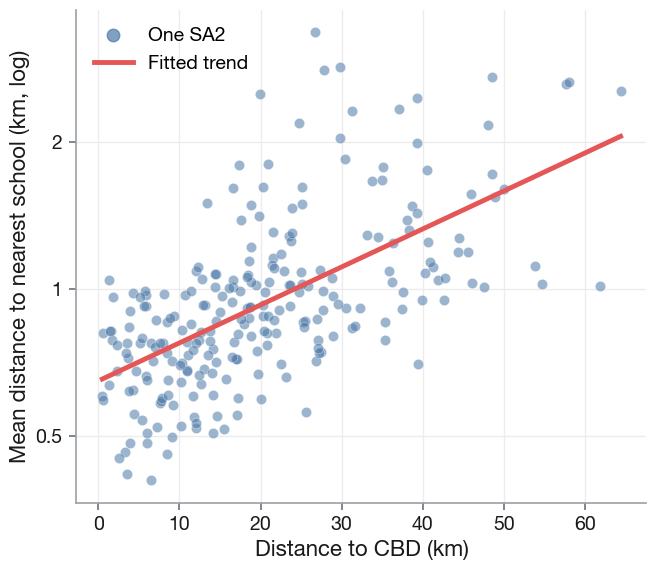

,SA2_NAME21,dist_cbd_km,avg_amenity_km,predicted_amenity_dist,true_pct_above_mean
0,Brunswick East,5.125791,0.776594,0.711484,0.091513
1,Brunswick West,5.868449,0.924552,0.721004,0.282311
2,Brunswick - North,5.880801,0.974691,0.721164,0.351553
3,Brunswick - South,4.676849,0.679652,0.705790,-0.037034
4,Coburg - East,7.584472,0.585575,0.743493,-0.212400


In [7]:
fit_df["predicted_amenity_dist"] = np.exp(amenity_fit.predict(X))
fit_df["true_pct_above_mean"] = (
    (fit_df["avg_amenity_km"] - fit_df["predicted_amenity_dist"])
    / fit_df["predicted_amenity_dist"]
)

# Linearized view: log(amenity) ~ dist  →  straight line on linear-x / log-y
x_line = np.linspace(fit_df["dist_cbd_km"].min(), fit_df["dist_cbd_km"].max(), 300)
fig, ax = plt.subplots(figsize=HALF)
scatter_sa2(ax, fit_df["dist_cbd_km"], fit_df["avg_amenity_km"])
ax.plot(
    x_line, np.exp(amenity_fit.predict(sm.add_constant(x_line))),
    color=FIT, linewidth=FIT_LW, zorder=3, label="Fitted",
)
ax.set_yscale("log")
log_axis(ax.yaxis, fit_df["avg_amenity_km"].min(), fit_df["avg_amenity_km"].max())
style_axes(ax, grid="both")
ax.set_xlabel("Distance to CBD (km)")
ax.set_ylabel(f"Mean distance to nearest {amenity_noun(AMENITY)} (km, log)")
ax.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", markersize=9, color=POINT, alpha=0.7, label="One SA2"),
        Line2D([], [], color=FIT, linewidth=FIT_LW, label="Fitted trend"),
    ],
    loc="upper left",
)
save(fig, "amenity_vs_cbd_fit.png")

fit_df.head()


## Rent per bedroom vs distance to CBD

Each point is one SA2. Rent per bedroom is `weekly_rent_number / bedrooms` on listings with at least one bedroom; the SA2 value is the mean of those ratios. The predictor is straight-line distance from the SA2 centroid to the CBD. Plotted on natural (linear) axes first; the fitted view below uses a log distance axis so the model reads as a straight line.

Rent SA2s retained (n_rent >= 10): 245


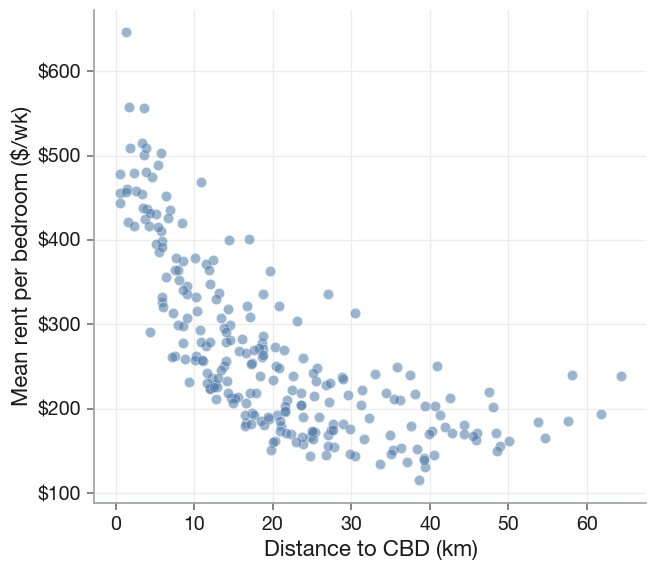

In [8]:
rentable = joined[
    joined["bedrooms"].gt(0) & joined["weekly_rent_number"].gt(0)
].copy()
rentable["rent_per_bedroom"] = rentable["weekly_rent_number"] / rentable["bedrooms"]

rent_by_sa2 = (
    rentable.groupby("SA2_NAME21")
    .agg(
        avg_rent_per_bedroom=("rent_per_bedroom", "mean"),
        n_rent_listings=("rent_per_bedroom", "size"),
    )
    .reset_index()
    .merge(sa2[["SA2_NAME21", "dist_cbd_km"]], on="SA2_NAME21", how="inner")
)
# Re-apply min-n on rentable counts (some eligible SA2s may lose listings after bed/rent filters)
rent_by_sa2 = rent_by_sa2[
    (rent_by_sa2["dist_cbd_km"] > 0) & (rent_by_sa2["n_rent_listings"] >= MIN_N)
].copy()

rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom"]].to_csv(
    "transformed_data/rent_per_bedroom_vs_distance_to_cbd.csv", index=False
)
print(f"Rent SA2s retained (n_rent >= {MIN_N}): {len(rent_by_sa2):,}")

# Natural shape (linear km) — linearized fit plot is after the model cell
fig, ax = plt.subplots(figsize=HALF)
scatter_sa2(ax, rent_by_sa2["dist_cbd_km"], rent_by_sa2["avg_rent_per_bedroom"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))
style_axes(ax, grid="both")
ax.set_xlabel("Distance to CBD (km)")
ax.set_ylabel("Mean rent per bedroom ($/wk)")
save(fig, "rent_vs_cbd.png")


### Fitting a model

Linear regression of mean rent per bedroom on log CBD distance (`rent ~ log(distance)`). On a log distance axis the fit is a straight line; on natural axes it is a decaying curve. `true_pct_above_mean` is how far the observed rent per bedroom sits above/below the predicted value for that SA2's CBD distance.

In [9]:
rent_fit_df = rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom"]].dropna().copy()
# Name the regressor honestly so the summary table doesn't say "dist_cbd_km" for a log term
X_rent = sm.add_constant(np.log(rent_fit_df["dist_cbd_km"]).rename("log_dist_cbd_km"))
y_rent = rent_fit_df["avg_rent_per_bedroom"]

rent_fit = sm.OLS(y_rent, X_rent).fit()
print(rent_fit.summary())


                             OLS Regression Results                             
Dep. Variable:     avg_rent_per_bedroom   R-squared:                       0.701
Model:                              OLS   Adj. R-squared:                  0.700
Method:                   Least Squares   F-statistic:                     569.9
Date:                  Mon, 19 Oct 2026   Prob (F-statistic):           1.17e-65
Time:                          22:50:26   Log-Likelihood:                -1335.7
No. Observations:                   245   AIC:                             2675.
Df Residuals:                       243   BIC:                             2682.
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             533.

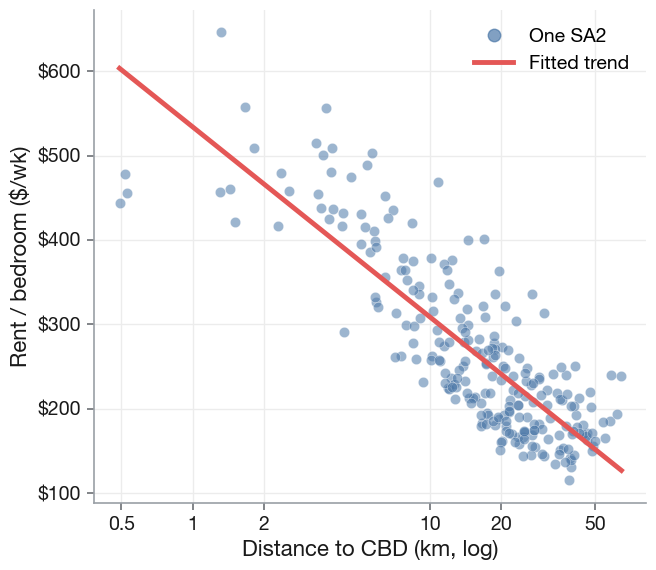

,SA2_NAME21,dist_cbd_km,avg_rent_per_bedroom,predicted_rent_per_bedroom,true_pct_above_mean
0,Abbotsford,3.380378,454.222222,415.029966,0.094432
1,Airport West,12.298999,236.969697,288.919241,-0.179806
2,Albert Park,3.555413,500.452381,410.100516,0.220316
3,Altona,14.028201,278.676471,276.073949,0.009427
4,Altona Meadows,17.412942,194.682540,254.968691,-0.236445


In [10]:
rent_fit_df["predicted_rent_per_bedroom"] = rent_fit.predict(X_rent)
rent_fit_df["true_pct_above_mean"] = (
    (rent_fit_df["avg_rent_per_bedroom"] - rent_fit_df["predicted_rent_per_bedroom"])
    / rent_fit_df["predicted_rent_per_bedroom"]
)

# Linearized view: rent ~ log(dist)  →  straight line on log-x / linear-y
x_min, x_max = rent_fit_df["dist_cbd_km"].min(), rent_fit_df["dist_cbd_km"].max()
x_line = np.logspace(np.log10(x_min), np.log10(x_max), 300)
fig, ax = plt.subplots(figsize=HALF)
scatter_sa2(ax, rent_fit_df["dist_cbd_km"], rent_fit_df["avg_rent_per_bedroom"])
ax.plot(
    x_line, rent_fit.predict(sm.add_constant(np.log(x_line))),
    color=FIT, linewidth=FIT_LW, zorder=3,
)
ax.set_xscale("log")
log_axis(ax.xaxis, x_min, x_max)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))
style_axes(ax, grid="both")
ax.set_xlabel("Distance to CBD (km, log)")
ax.set_ylabel("Rent / bedroom ($/wk)")
ax.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", markersize=9, color=POINT, alpha=0.7, label="One SA2"),
        Line2D([], [], color=FIT, linewidth=FIT_LW, label="Fitted trend"),
    ],
    loc="upper right",
)
save(fig, "rent_vs_cbd_fit.png")

rent_fit_df.head()


## Slide figure: rent vs amenity access, side by side

Both fitted models on one shared **natural** (linear km) CBD-distance axis, so the two panels read as one story: moving out saves rent but costs amenity access. Fits appear in their natural shapes (log decay for rent; exponential growth for amenity). Subtitles translate each coefficient into plain English. Exported at full slide width (13.33 in) as `rent_amenity_fits_side_by_side.png`.

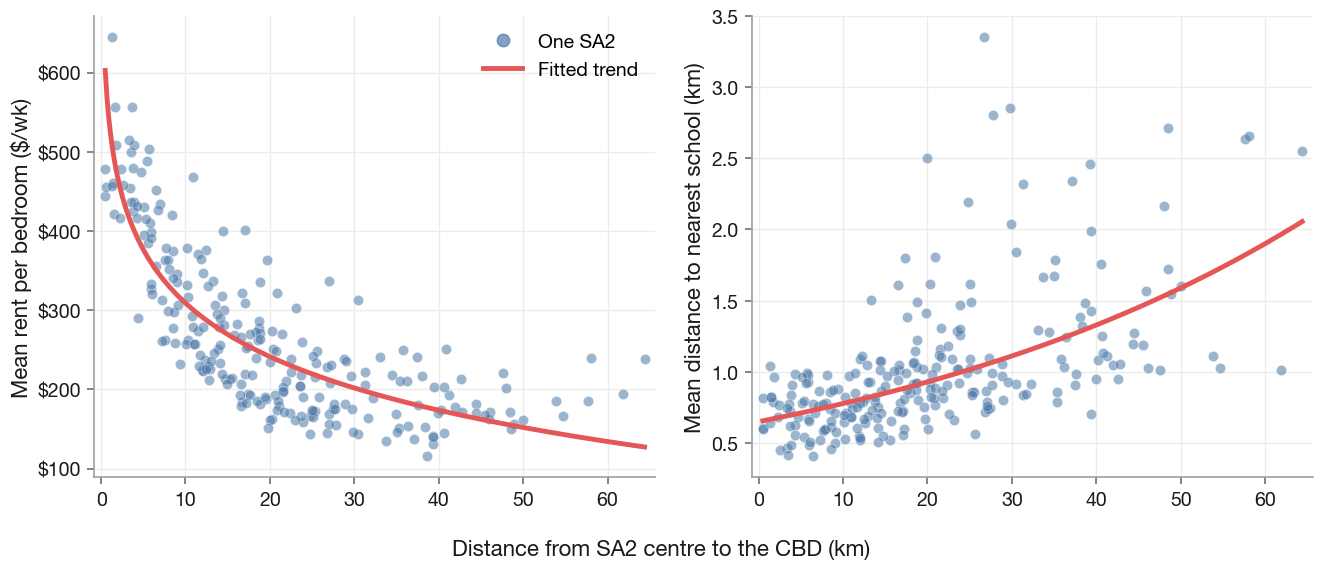

In [11]:
noun = amenity_noun(AMENITY)

# Shared natural (linear km) axis — both fits show their true curved shapes
all_x = pd.concat([rent_fit_df["dist_cbd_km"], fit_df["dist_cbd_km"]])
x_min, x_max = float(all_x.min()), float(all_x.max())
x_line = np.linspace(x_min, x_max, 300)

fig, (ax_rent, ax_amen) = plt.subplots(1, 2, figsize=PAIR, sharex=True)

# ── Left: rent per bedroom ────────────────────────────────────────────────────
scatter_sa2(ax_rent, rent_fit_df["dist_cbd_km"], rent_fit_df["avg_rent_per_bedroom"])
ax_rent.plot(
    x_line, rent_fit.predict(sm.add_constant(np.log(x_line))),
    color=FIT, linewidth=FIT_LW, zorder=3,
)
ax_rent.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))
ax_rent.set_ylabel("Mean rent per bedroom ($/wk)")

# ── Right: distance to nearest amenity ────────────────────────────────────────
scatter_sa2(ax_amen, fit_df["dist_cbd_km"], fit_df["avg_amenity_km"])
ax_amen.plot(
    x_line, np.exp(amenity_fit.predict(sm.add_constant(x_line))),
    color=FIT, linewidth=FIT_LW, zorder=3,
)
ax_amen.set_ylabel(f"Mean distance to nearest {noun} (km)")

# ── Shared styling ────────────────────────────────────────────────────────────
ax_rent.set_xlim(x_min - 0.02 * (x_max - x_min), x_max + 0.02 * (x_max - x_min))
for ax in (ax_rent, ax_amen):
    style_axes(ax, grid="both")
fig.supxlabel("Distance from SA2 centre to the CBD (km)", fontsize=16, color=INK)

ax_rent.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", markersize=9, color=POINT, alpha=0.7, label="One SA2"),
        Line2D([], [], color=FIT, linewidth=FIT_LW, label="Fitted trend"),
    ],
    loc="upper right",
)

save(fig, "rent_amenity_fits_side_by_side.png")


## Affordability–Amenity Access Tradeoff

Each SA2 is placed by how far it sits above/below what its CBD distance predicts:
- **x** = rent per bedroom residual (`rent_pct_above_mean`)
- **y** = amenity-distance residual (`amenity_pct_above_mean`)

**Renter score** = `−x − y`. Cheaper-than-expected rent *and* closer-than-expected amenities both raise the score (bottom-left). The reverse lowers it (top-right). The background and dots share that gradient; axes are centred on the origin (fully "as expected").


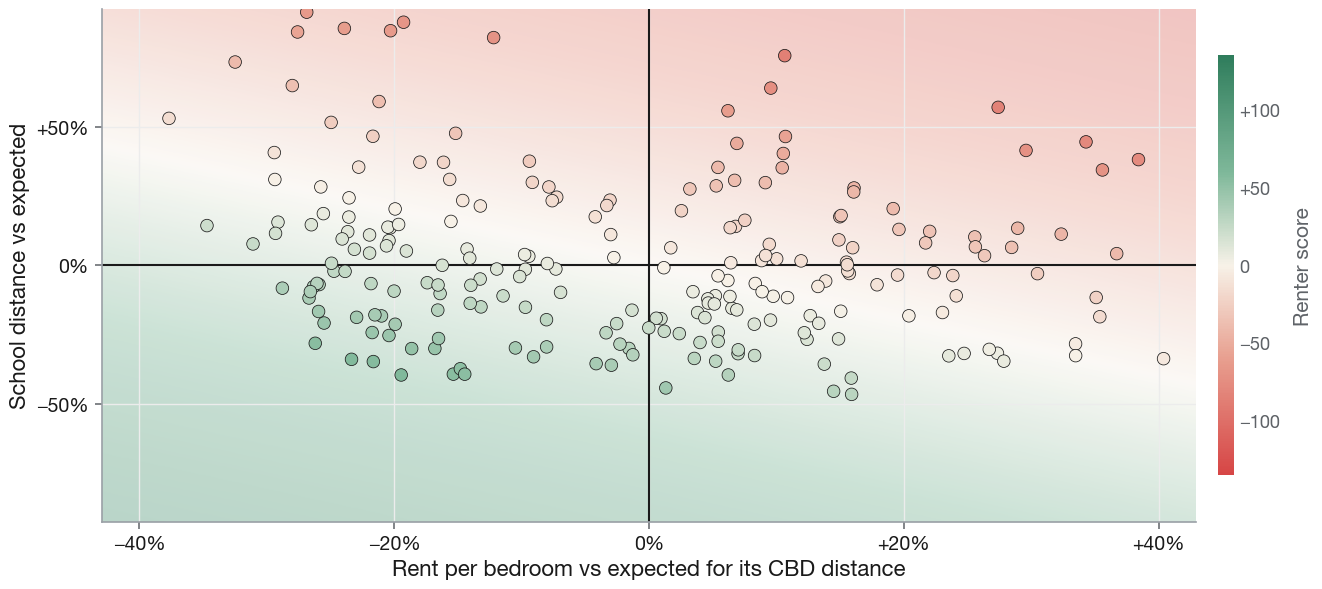

,SA2_NAME21,rent_pct_above_mean,amenity_pct_above_mean,renter_score
0,Abbotsford,0.094432,0.075477,-0.169910
1,Airport West,-0.179806,0.371615,-0.191809
2,Albert Park,0.220316,0.122257,-0.342573
3,Altona,0.009427,-0.192393,0.182966
4,Altona Meadows,-0.236445,0.120946,0.115500


In [12]:
tradeoff = (
    rent_fit_df[["SA2_NAME21", "true_pct_above_mean"]]
    .rename(columns={"true_pct_above_mean": "rent_pct_above_mean"})
    .merge(
        fit_df[["SA2_NAME21", "true_pct_above_mean"]].rename(
            columns={"true_pct_above_mean": "amenity_pct_above_mean"}
        ),
        on="SA2_NAME21",
        how="inner",
    )
)

# Higher = better for a renter (cheaper than expected AND closer amenities than expected)
tradeoff["renter_score"] = -tradeoff["rent_pct_above_mean"] - tradeoff["amenity_pct_above_mean"]

# Zoom to central mass (5th–95th percentile), then centre the origin on both axes
x_lo, x_hi = tradeoff["rent_pct_above_mean"].quantile([0.05, 0.95])
y_lo, y_hi = tradeoff["amenity_pct_above_mean"].quantile([0.05, 0.95])
x_pad = 0.10 * (x_hi - x_lo)
y_pad = 0.10 * (y_hi - y_lo)
x_span = max(abs(float(x_lo - x_pad)), abs(float(x_hi + x_pad)))
y_span = max(abs(float(y_lo - y_pad)), abs(float(y_hi + y_pad)))
x_lo, x_hi = -x_span, x_span
y_lo, y_hi = -y_span, y_span

noun = amenity_noun(AMENITY)
fig, ax = plt.subplots(figsize=FULL)

# Soft renter-score wash: a pale copy of RENTER_CMAP so the background never competes with the dots
def _soften(cmap, mix=0.55, n=512):
    cols = cmap(np.linspace(0, 1, n))[:, :3]
    return LinearSegmentedColormap.from_list("renter_soft", cols * (1 - mix) + mix, N=n)

BG_CMAP = _soften(RENTER_CMAP)

gx = np.linspace(x_lo, x_hi, 400)
gy = np.linspace(y_lo, y_hi, 400)
GX, GY = np.meshgrid(gx, gy)
GZ = -GX - GY
score_lim = float(np.max(np.abs(GZ)))
score_norm = TwoSlopeNorm(vmin=-score_lim, vcenter=0.0, vmax=score_lim)

# tanh eases the ramp so colour builds up slowly away from the neutral diagonal
bg_lim = 0.9 * score_lim
ax.imshow(
    bg_lim * np.tanh(GZ / bg_lim),
    extent=[x_lo, x_hi, y_lo, y_hi],
    origin="lower",
    cmap=BG_CMAP,
    norm=score_norm,
    aspect="auto",
    alpha=0.9,
    interpolation="bicubic",
    zorder=0,
)

sc = ax.scatter(
    tradeoff["rent_pct_above_mean"],
    tradeoff["amenity_pct_above_mean"],
    c=tradeoff["renter_score"],
    cmap=RENTER_CMAP,
    norm=score_norm,
    s=82,
    alpha=1.0,
    edgecolor="#1a1a1a",
    linewidth=0.55,
    zorder=3,
)

ax.axhline(0, color="#1a1a1a", linewidth=1.5, zorder=2)
ax.axvline(0, color="#1a1a1a", linewidth=1.5, zorder=2)

style_axes(ax, grid="both")
ax.set_xlim(x_lo, x_hi)
ax.set_ylim(y_lo, y_hi)
ax.set_xmargin(0)
ax.set_ymargin(0)

cbar = fig.colorbar(sc, ax=ax, fraction=0.035, shrink=0.82, aspect=26, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label("Renter score", fontsize=15, color=MUTED, labelpad=10)
cbar.ax.tick_params(length=0, labelsize=13, colors=MUTED)
cbar.ax.yaxis.set_major_formatter(
    FuncFormatter(lambda v, _: f"{100 * v:+.0f}".replace("-", "−") if abs(v) > 1e-9 else "0")
)

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(MaxNLocator(nbins=7, steps=[1, 2, 5, 10]))
    axis.set_major_formatter(
        FuncFormatter(lambda v, _: f"{100 * v:+.0f}%".replace("-", "−") if abs(v) > 1e-9 else "0%")
    )
ax.set_xlabel("Rent per bedroom vs expected for its CBD distance")
ax.set_ylabel(f"{noun.capitalize()} distance vs expected")

save(fig, "affordability_amenity_tradeoff.png")

tradeoff.head()


### Interactive explorer

Hover any SA2 to see how its rent and amenity access compare to the CBD-distance expectation. Colour encodes a simple renter score (cheaper + closer amenities than expected → greener). Rings mark distance from the origin (fully "as expected"). Opens as a standalone HTML file.

In [13]:
import plotly.graph_objects as go

explorer = (
    tradeoff.merge(
        rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom", "n_rent_listings"]],
        on="SA2_NAME21",
        how="inner",
    )
    .merge(
        fit_df[["SA2_NAME21", "avg_amenity_km", "predicted_amenity_dist"]],
        on="SA2_NAME21",
        how="inner",
    )
    .merge(
        rent_fit_df[["SA2_NAME21", "predicted_rent_per_bedroom"]],
        on="SA2_NAME21",
        how="inner",
    )
)

# renter_score and axis limits (x_lo/x_hi/y_lo/y_hi) come from the static tradeoff cell
explorer["residual_radius"] = np.sqrt(
    explorer["rent_pct_above_mean"] ** 2 + explorer["amenity_pct_above_mean"] ** 2
)

def _quadrant(row):
    cheap = row["rent_pct_above_mean"] < 0
    good_amenity = row["amenity_pct_above_mean"] < 0
    if cheap and good_amenity:
        return "Affordable · Good amenity access"
    if cheap and not good_amenity:
        return "Affordable · Poor amenity access"
    if (not cheap) and good_amenity:
        return "Expensive · Good amenity access"
    return "Expensive · Poor amenity access"

explorer["quadrant"] = explorer.apply(_quadrant, axis=1)

# Soft renter-score wash under the points (same definition as the static chart)
gx = np.linspace(x_lo, x_hi, 120)
gy = np.linspace(y_lo, y_hi, 120)
GX, GY = np.meshgrid(gx, gy)
GZ = -GX - GY
score_lim = float(np.max(np.abs(GZ)))

fig = go.Figure()

fig.add_trace(
    go.Contour(
        x=gx,
        y=gy,
        z=GZ,
        zmin=-score_lim,
        zmax=score_lim,
        colorscale=[
            [0.0, "rgba(214, 69, 69, 0.70)"],
            [0.28, "rgba(232, 160, 144, 0.55)"],
            [0.5, "rgba(247, 242, 232, 0.22)"],
            [0.72, "rgba(127, 184, 154, 0.55)"],
            [1.0, "rgba(47, 125, 92, 0.70)"],
        ],
        showscale=False,
        hoverinfo="skip",
        contours=dict(showlines=False, coloring="heatmap"),
        name="renter score",
    )
)

hover_text = [
    (
        f"<b>{r.SA2_NAME21}</b><br>"
        f"<span style='color:#6b7280'>{r.quadrant}</span><br><br>"
        f"Rent vs expectation: <b>{100 * r.rent_pct_above_mean:+.0f}%</b>"
        f"  (${r.avg_rent_per_bedroom:,.0f}/bed · expect ${r.predicted_rent_per_bedroom:,.0f})<br>"
        f"Amenity distance vs expectation: <b>{100 * r.amenity_pct_above_mean:+.0f}%</b>"
        f"  ({r.avg_amenity_km:.2f} km · expect {r.predicted_amenity_dist:.2f} km)<br>"
        f"Distance to CBD: {r.dist_cbd_km:.1f} km<br>"
        f"Listings in sample: {int(r.n_rent_listings)}"
    )
    for r in explorer.itertuples()
]

fig.add_trace(
    go.Scatter(
        x=explorer["rent_pct_above_mean"],
        y=explorer["amenity_pct_above_mean"],
        mode="markers",
        marker=dict(
            size=10,
            color=explorer["renter_score"],
            colorscale=[
                [0.0, "#D64545"],
                [0.28, "#E8A090"],
                [0.5, "#F7F2E8"],
                [0.72, "#7FB89A"],
                [1.0, "#2F7D5C"],
            ],
            cmid=0,
            cmin=-score_lim,
            cmax=score_lim,
            opacity=0.88,
            line=dict(width=0.6, color="rgba(255,255,255,0.85)"),
            colorbar=dict(
                title=dict(text="Renter score", side="right"),
                thickness=14,
                len=0.55,
                outlinewidth=0,
                bgcolor="rgba(255,255,255,0)",
                tickfont=dict(size=11, color="#5c6370"),
            ),
        ),
        text=hover_text,
        hoverinfo="text",
        name="SA2",
    )
)

# Axis cross at expectation
fig.add_hline(y=0, line=dict(color="rgba(40, 44, 52, 0.55)", width=1.4))
fig.add_vline(x=0, line=dict(color="rgba(40, 44, 52, 0.55)", width=1.4))

fig.update_layout(
    paper_bgcolor="#ffffff",
    plot_bgcolor="rgba(0,0,0,0)",
    font=dict(family="Helvetica Neue, Arial, sans-serif", color="#333333", size=14),
    margin=dict(l=70, r=90, t=30, b=60),
    width=980,
    height=780,
    hoverlabel=dict(
        bgcolor="rgba(255, 255, 255, 0.97)",
        bordercolor="rgba(60, 64, 72, 0.15)",
        font=dict(size=13, color="#111111", family="Helvetica Neue, Arial, sans-serif"),
        align="left",
    ),
    xaxis=dict(
        title="Rent per bedroom vs CBD-distance expectation",
        range=[x_lo, x_hi],
        tickformat=".0%",
        zeroline=False,
        showgrid=True,
        gridcolor="rgba(60, 64, 72, 0.08)",
        gridwidth=1,
        linecolor="rgba(60, 64, 72, 0.25)",
    ),
    yaxis=dict(
        title="Amenity distance vs CBD-distance expectation",
        range=[y_lo, y_hi],
        tickformat=".0%",
        zeroline=False,
        showgrid=True,
        gridcolor="rgba(60, 64, 72, 0.08)",
        gridwidth=1,
        linecolor="rgba(60, 64, 72, 0.25)",
    ),
    showlegend=False,
)

out_path = Path("transformed_data") / "affordability_amenity_tradeoff.html"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.write_html(out_path, include_plotlyjs="cdn", full_html=True, config={"displayModeBar": False})
print(f"Wrote {out_path.resolve()}")


Wrote /Users/aditya/Library/CloudStorage/GoogleDrive-writetoadityay@gmail.com/Other computers/My Mac/MyMac_GoogleDrive/University/2026/Semester 2/MAST30034/real-estate-industry-project/modelling/liveability/transformed_data/affordability_amenity_tradeoff.html
